In [1]:
!apt-get install -y poppler-utils tesseract-ocr
!pip install -q "unstructured[pdf]" detectron2@git+https://github.com/facebookresearch/detectron2.git@v0.6#egg=detectron2

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
tesseract-ocr is already the newest version (4.1.1-2.1build1).
The following NEW packages will be installed:
  poppler-utils
0 upgraded, 1 newly installed, 0 to remove and 42 not upgraded.
Need to get 186 kB of archives.
After this operation, 697 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy-updates/main amd64 poppler-utils amd64 22.02.0-2ubuntu0.12 [186 kB]
Fetched 186 kB in 0s (2,915 kB/s)
Selecting previously unselected package poppler-utils.
(Reading database ... 122354 files and directories currently installed.)
Preparing to unpack .../poppler-utils_22.02.0-2ubuntu0.12_amd64.deb ...
Unpacking poppler-utils (22.02.0-2ubuntu0.12) ...
Setting up poppler-utils (22.02.0-2ubuntu0.12) ...
Processing triggers for man-db (2.10.2-1) ...
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 53.9 MB/s eta 0:00:0

In [2]:
from google.colab import files

uploaded = files.upload()
pdf_path = list(uploaded.keys())[0]
print(f'Uploaded: {pdf_path}')

Saving EBSCO-FullText-06_11_20242.pdf to EBSCO-FullText-06_11_20242.pdf
Uploaded: EBSCO-FullText-06_11_20242.pdf


In [4]:
# Cell 3: Parse the PDF
import os
from unstructured.partition.pdf import partition_pdf

output_dir = "/content/extracted_images"
if not os.path.exists(output_dir):
    os.makedirs(output_dir)



elements = partition_pdf(
    filename="test_ankh.pdf",
    strategy="hi_res",
    extract_images_in_pdf=True,
    extract_image_block_output_dir=output_dir,
    infer_table_structure=True,
    chunking_strategy="by_title",
    max_characters=4000,
    combine_text_under_n_chars=200
)

full_text = ""
for element in elements:
    if "Table" in str(type(element)):
        full_text += f"\n[Table Found]: {element.metadata.text_as_html}\n"
    else:
        full_text += f"\n{element.text}\n"


print("Partitioning Complete!")
print(f"Total Text Length: {len(full_text)} characters")
print(f"Images Extracted: {len(os.listdir(output_dir))}")

preprocessor_config.json:   0%|          | 0.00/274 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/115M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/46.8M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/367 [00:00<?, ?it/s]

Partitioning Complete!
Total Text Length: 30278 characters
Images Extracted: 8


In [5]:
text_file_path = "/content/extracted_text.txt"

with open(text_file_path, "w", encoding="utf-8") as f:
    f.write(full_text)

###Extracted Text


S

S

Nefertiti: New Perspectives from New Data

New evidence about Nefertiti has altered perspectives and theories surrounding this Queen, and possible Pharaoh, from ancient Egypt.

Jack T. Norris

The University of Melbourne

Grace O’Donnell

History Educator

Through her legendary painted bust, Queen Nefertiti has become one of the most famous figures from ancient Egypt. Yet many of the discussions surrounding Nefertiti, her family and this era of ancient Egyptian history have ‘been going around in circles for over a century’.1 New evidence in the past fifteen years has sparked ‘new ways to look at old data—that make even quite recent works obsolescent regarding aspects of Nefertiti’s career’.2

This article explores new evidence and scholarly perspectives on Nefertiti’s possible elevation to pharaoh and co-regent, her possible parentage of Tutankhamun, and current discussions surrounding the identification of her mummy and tomb.

The painted limestone bust of Nefertiti sporting he

---

### Extracted images

** photo: figure-4-6.jpg**

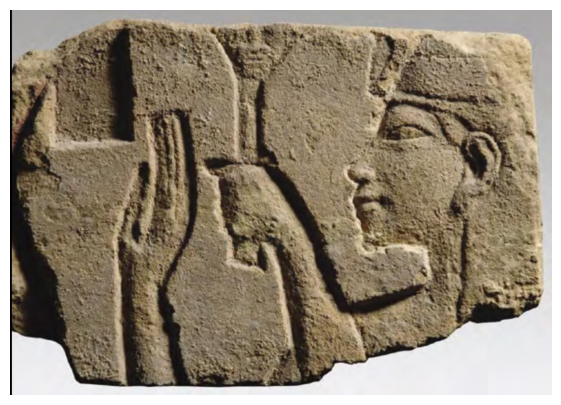

---

** photo: figure-1-1.jpg**

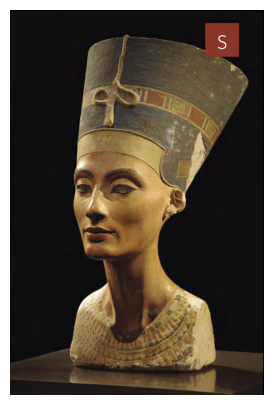

---

** photo: figure-3-5.jpg**

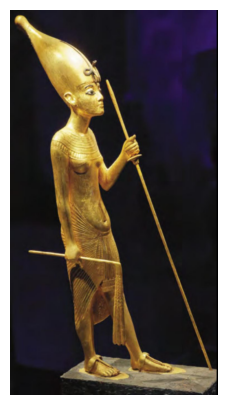

---

** photo: figure-2-2.jpg**

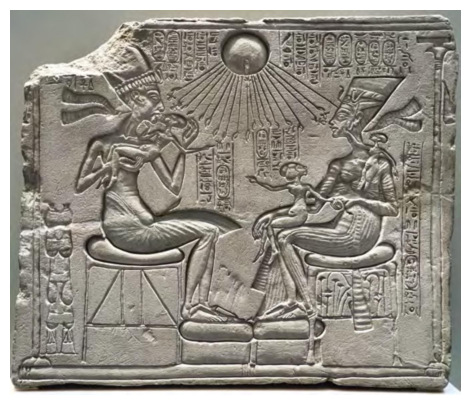

---

** photo: figure-2-3.jpg**

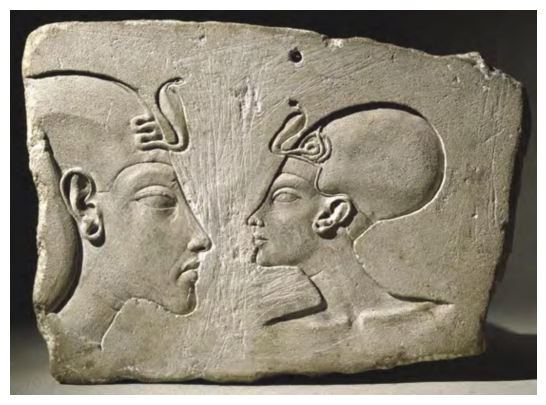

---

** photo: figure-3-4.jpg**

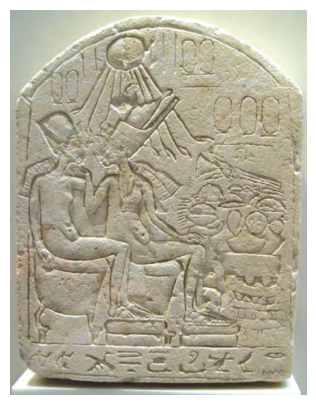

---

** photo: figure-5-7.jpg**

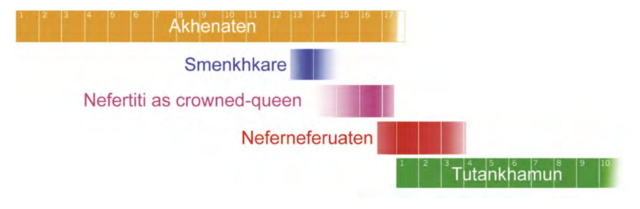

---

** photo: figure-5-8.jpg**

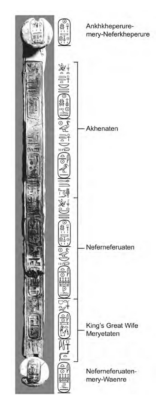

---

###

In [6]:
import os
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

text_blocks =[]
tables =[]
images =[]

display(Markdown("###Extracted Text"))
print(full_text[:] + "...")

display(Markdown("---"))

display(Markdown("### Extracted images"))

image_folder = "/content/extracted_images"
image_files = [f for f in os.listdir(image_folder) if f.endswith(('.png', '.jpg', '.jpeg'))]

if not image_files:
    print("Not Found")
else:
    for img_name in image_files:
        img_path = os.path.join(image_folder, img_name)

        display(Markdown(f"** photo: {img_name}**"))

        img = Image.open(img_path)
        plt.figure(figsize=(8, 5))
        plt.imshow(img)
        plt.axis('off')
        plt.show()

        display(Markdown("---"))

display(Markdown("###"))


In [7]:
!pip install -q transformers accelerate bitsandbytes qwen-vl-utils pillow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.3/36.3 MB 20.5 MB/s eta 0:00:00


In [8]:
import torch
from transformers import Qwen2_5_VLForConditionalGeneration, AutoProcessor
from google.colab import userdata

model_id = "Qwen/Qwen2.5-VL-3B-Instruct"

# Quantization 4 bit
model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    model_id,
    torch_dtype=torch.bfloat16,
    device_map="auto"
)

processor = AutoProcessor.from_pretrained(model_id)

config.json: 0.00B [00:00, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

... (2 outputs left out)

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [9]:
import os
import torch
from qwen_vl_utils import process_vision_info
from IPython.display import display, Markdown
from PIL import Image

with open("/content/extracted_text.txt", "r", encoding="utf-8") as f:
    clean_context = f.read()

min_pixels = 256 * 28 * 28
max_pixels = 512 * 28 * 28

image_dir = "/content/extracted_images"
all_image_files = [f for f in os.listdir(image_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.gif', '.bmp'))]
valid_image_paths = []

for fname in all_image_files[:5]:
    img_path = os.path.join(image_dir, fname)
    try:
        with Image.open(img_path) as img:
            width, height = img.size
            if width > 0 and height > 0:
                valid_image_paths.append(img_path)
            else:
                print(f"Skipping invalid image (zero dimension): {fname}")
    except Exception as e:
        print(f"Skipping corrupted or unreadable image {fname}: {e}")

messages = [
    {
        "role": "user",
        "content": [
            *[{"type": "image", "image": f"file://{os.path.abspath(img_path)}", "min_pixels": min_pixels, "max_pixels": max_pixels}
              for img_path in valid_image_paths],

            {"type": "text", "text": f"""
            Using the provided high-quality text and images:
            1. Write a (3-4)paragraph executive summary about the museum's collection.
            2. Create a clean Markdown table for the main artifacts mentioned.
            3. Mention the historical significance of the Alexandria-related pieces.

            Context from File:
            {clean_context[:5000]}
            """}
        ],
    }
]

text_input = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
image_inputs, video_inputs = process_vision_info(messages)
inputs = processor(text=[text_input], images=image_inputs, videos=video_inputs, padding=True, return_tensors="pt").to("cuda")

with torch.no_grad():
    generated_ids = model.generate(**inputs, max_new_tokens=3500)

final_output = processor.batch_decode(generated_ids[:, inputs.input_ids.shape[1]:], skip_special_tokens=True)[0]

display(Markdown(final_output))

### Executive Summary

The museum's collection offers a rich and diverse array of artifacts that provide invaluable insights into ancient Egyptian history, culture, and artistry. The collection includes iconic pieces such as the painted limestone bust of Nefertiti, a significant figure in ancient Egyptian history, and a gold statue of Akhenaten, showcasing the artistic achievements of the Eighteenth Dynasty. These artifacts not only highlight the cultural and religious practices of ancient Egypt but also offer a glimpse into the political and social structures of the time. The collection is particularly noteworthy for its ability to challenge and expand our understanding of historical narratives, as evidenced by the recent research on Nefertiti and her possible role in the Amarna period. The museum's commitment to preserving and interpreting these artifacts ensures that future generations can continue to learn and appreciate the rich legacy of ancient Egypt.

### Markdown Table for Main Artifacts

| Artifact | Description | Location |
|----------|-------------|----------|
| Painted Limestone Bust of Nefertiti | Bust of Nefertiti wearing her unique blue flat-top crown | Museum of Fine Arts, Boston |
| Gold Statue of Akhenaten | Statue of Akhenaten holding a staff | Metropolitan Museum of Art, New York City |
| Relief Sketch of Akhenaten and Nefertiti | Sketch depicting the couple with three daughters | Brooklyn Museum |

### Historical Significance of Alexandria-Related Pieces

The museum's collection also includes several artifacts related to Alexandria, a major city in ancient Egypt. These pieces provide insight into the cultural and economic ties between Alexandria and other parts of Egypt. For example, the collection features a relief sketch of Akhenaten and Nefertiti, which highlights the religious and artistic significance of the Amarna period. Additionally, the museum holds a gold statue of Akhenaten, which showcases the artistic achievements of the Eighteenth Dynasty. These artifacts not only reflect the cultural diversity of ancient Egypt but also underscore the importance of Alexandria as a hub of trade and commerce during this period. The museum's collection serves as a testament to the enduring legacy of Alexandria and its role in shaping ancient Egyptian history.

**Tring Different Prompt Template**

In [10]:
torch.cuda.empty_cache()
#3. Prompt Template
messages = [
    {
        "role": "user",
        "content": [
            *[{"type": "image", "image": f"file://{os.path.abspath(img_path)}", "min_pixels": min_pixels, "max_pixels": max_pixels}
              for img_path in valid_image_paths],

            {"type": "text", "text": f"""
             You are an expert Museum Curator and Historian.
            Generate a 'Curator's Summary' for the provided Greco-Roman artifacts.
            .

              Structure:
              1. Executive Overview
              2. Artifact Analysis (Name, Material, Era)
              3. Visual Correlation (Link images to text)
              4. Historical Significance

              Context from File:
              {clean_context[:5000]}
              """}
                      ]
                  }
              ]

text_input = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
image_inputs, video_inputs = process_vision_info(messages)
inputs = processor(text=[text_input], images=image_inputs, videos=video_inputs, padding=True, return_tensors="pt").to("cuda")

with torch.no_grad():
    generated_ids = model.generate(**inputs, max_new_tokens=3500)

final_output = processor.batch_decode(generated_ids[:, inputs.input_ids.shape[1]:], skip_special_tokens=True)[0]

display(Markdown(final_output))

### Curator's Summary

#### Executive Overview
This curator's summary provides an overview of the historical significance and visual analysis of three significant artifacts related to ancient Egyptian history, particularly focusing on the Eighteenth Dynasty and the Amarna Period. The artifacts include a painted limestone bust of Nefertiti, a gold statue of Akhenaten, and a relief sketch depicting Akhenaten and Nefertiti. These artifacts offer insights into the religious, political, and cultural aspects of ancient Egypt during this transformative era.

#### Artifact Analysis
1. **Painted Limestone Bust of Nefertiti**
   - **Material:** Painted limestone
   - **Era:** New Kingdom, 18th Dynasty (c. 1337–1321 BCE)
   - **Description:** This bust is a remarkable example of ancient Egyptian art, showcasing Nefertiti's distinctive blue flat-top crown and her role as the "Great Royal Wife" of Akhenaten. The bust is believed to have been created during the Amarna Period, a time of religious and artistic innovation under Akhenaten's rule.

2. **Gold Statue of Akhenaten**
   - **Material:** Gold
   - **Era:** New Kingdom, 18th Dynasty (c. 1337–1321 BCE)
   - **Description:** This statue is a striking representation of Akhenaten, the "Heretic Pharaoh," who introduced the Atenist religion. The statue depicts Akhenaten holding a staff, symbolizing his authority and connection to the Aten. The detailed craftsmanship and the inclusion of the Aten symbol highlight the religious significance of this period.

3. **Relief Sketch of Akhenaten and Nefertiti**
   - **Material:** Stone
   - **Era:** New Kingdom, 18th Dynasty (c. 1352–1336 BCE)
   - **Description:** This relief sketch captures a family scene featuring Akhenaten and Nefertiti, along with their three daughters. The depiction emphasizes the royal family's unity and the prominence of Nefertiti within the dynasty. The presence of the Aten symbol underscores the religious focus of this period.

#### Visual Correlation
- **Bust of Nefertiti:** The bust prominently features Nefertiti's blue flat-top crown, which is a distinctive attribute of her royal status. The bust is a testament to her influence and the artistic achievements of the Amarna Period.
- **Statue of Akhenaten:** The gold statue of Akhenaten highlights his role as the "Heretic Pharaoh" and the central figure in the Atenist religion. The inclusion of the Aten symbol and the staff symbolize his divine authority and the religious reforms he initiated.
- **Relief Sketch:** The relief sketch illustrates the family unity and the prominence of Nefertiti within the royal family. The depiction of the Aten symbol further emphasizes the religious significance of this period.

#### Historical Significance
- **Nefertiti and Akhenaten:** The bust of Nefertiti and the statue of Akhenaten provide insights into the personal and political relationships within the royal family during the Amarna Period. Nefertiti's role as the "Great Royal Wife" and her adoption of the Atenist name reflect her influence and the religious changes brought about by Akhenaten.
- **Religious Reforms:** The relief sketch of Akhenaten and Nefertiti underscores the religious reforms initiated by Akhenaten, including the focus on the Aten and the exclusion of other deities. This period marked a significant shift in Egyptian religious practices and artistic expression.
- **Family Unity:** The family scene in the relief sketch highlights the importance of family unity and the royal family's role in maintaining order and stability during this transformative era.

These artifacts collectively offer a rich understanding of the Eighteenth Dynasty and the Amarna Period, shedding light on the political, religious, and cultural developments of ancient Egypt.

In [11]:
torch.cuda.empty_cache()

messages = [
    {
        "role": "user",
        "content": [

            *[{"type": "image", "image": f"file://{os.path.abspath(path)}", "min_pixels": min_pixels, "max_pixels": max_pixels} for path in valid_image_paths[:1]],

            {"type": "text", "text": "بناءً على النص والصور المرفقة، اشرح لي بأسلوب قصصي بسيط وباللغة العربية: ما هي محتويات هذا الجزء من المتحف؟ وما هي أهمية هذه القطع في تاريخ مصر؟)"}
        ],
    }
]


text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
image_inputs, video_inputs = process_vision_info(messages)
inputs = processor(text=[text], images=image_inputs, videos=video_inputs, padding=True, return_tensors="pt").to("cuda")

with torch.no_grad():
    generated_ids = model.generate(**inputs, max_new_tokens=512)

from IPython.display import display, Markdown
output_text = processor.batch_decode(generated_ids[0][len(inputs.input_ids[0]):], skip_special_tokens=True)[0]

display(Markdown("### 📝 التلخيص بالعربي:"))
display(Markdown(output_text))

### 📝 التلخيص بالعربي:

هذا الجزء من المتحف يعرض مجموعة من القطع الأثرية المصرية القديمة. إليك توضيحًا بسيطًا:

1. المحتوى:
- تمثل هذه القطع أجزاء من تماثيل وتماثيل حجرية.
- تظهر شخصيات تاريخية مهمة في مصر القديمة.
- بعضها يظهر شخصيات رسمية أو عامة.

2. أهمية القطع:
- هذه القطع مهمة جداً في تاريخ مصر لأنها تظهر:
  - التقاليد والعادات الاجتماعية في مصر القديمة.
  - التطورات في الفن والعمارة المصرية.
  - شخصيات هامة في التاريخ المصري القديم.
  - القيم الدينية والروحية في المجتمع المصري القديم.

- هذه القطع تساعد في فهم الثقافة والحضارة المصرية القديمة بشكل أفضل.
- تعتبر مصدراً هاماً لدراسة تاريخ مصر وتطورها الاجتماعي والثقافي.

- بعض هذه القطع قد تظهر آثار حضارات أخرى مثل الحبشة أو الأمازيغ، مما يعكس العلاقات بين مصر والدول المجاورة في ذلك الوقت.

هذه القطع ليست فقط أثراً تاريخياً، بل هي أيضاً جزءاً من الفن والثقافة المصرية القديمة، مما يجعلها مهمة جداً للعلماء والمهتمين بالفن والثقافة المصرية.

In [12]:
torch.cuda.empty_cache()


chunk_size = 2
all_artifacts_data = []

print("Starting Full Document Processing...")

for i in range(0, len(valid_image_paths), chunk_size):
    current_images = valid_image_paths[i : i + chunk_size]

    start_idx = i * 1000
    end_idx = (i + chunk_size) * 1500
    current_text_chunk = clean_context[start_idx : end_idx]


messages = [
    {
        "role": "user",
        "content": [
            *[{"type": "image", "image": f"file://{os.path.abspath(path)}", "min_pixels": min_pixels, "max_pixels": max_pixels} for path in current_images],

            {"type": "text", "text": """
            You are a museum curator. Based on all the images and the provided text from the PDF:
            1. Write a high-level summary (2 paragraphs) of what this document is about.
            2. Mention the 3 most important historical periods discussed.
            3. Describe the overall artistic style and significance of this collection.
            Output should be in clear English.
            """}
        ],
    }
]

text_input = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
image_inputs, video_inputs = process_vision_info(messages)
inputs = processor(text=[text_input], images=image_inputs, videos=video_inputs, padding=True, return_tensors="pt").to("cuda")

with torch.no_grad():
    generated_ids = model.generate(**inputs, max_new_tokens=1000)

output_summary = processor.batch_decode(generated_ids[:, inputs.input_ids.shape[1]:], skip_special_tokens=True)[0]

display(Markdown("# 📜 Executive Summary of the Document"))
display(Markdown(output_summary))

Starting Full Document Processing...


# 📜 Executive Summary of the Document

### High-Level Summary

This document appears to be an inventory or catalog entry for a collection of ancient Egyptian artifacts, specifically focusing on sculptures and reliefs. The entries detail various items such as statues, busts, and relief panels, each accompanied by descriptions that include dimensions, materials, and provenance details. The collection likely includes works from different periods of Egyptian history, showcasing the evolution of artistic styles and themes over time.

### Most Important Historical Periods Discussed

1. **Old Kingdom (2686-2181 BCE)**: This period is characterized by the construction of monumental architecture and the development of a centralized state. Artistic styles during this time were highly stylized and formal, with a focus on divine and royal imagery.

2. **Middle Kingdom (2055-1650 BCE)**: The Middle Kingdom saw a return to more naturalistic and humanistic styles in art. This period is known for its detailed depictions of everyday life and the emergence of new artistic techniques.

3. **New Kingdom (1550-1070 BCE)**: The New Kingdom is marked by significant advancements in sculpture and relief work. This period is famous for its grandiose tombs and the depiction of royal figures in dynamic poses, reflecting the power and wealth of the pharaohs.

### Overall Artistic Style and Significance

The collection reflects the rich and diverse artistic heritage of ancient Egypt, spanning three major periods. The Old Kingdom's formal and stylized art is evident in the detailed depictions of deities and royal figures. The Middle Kingdom's more naturalistic style is highlighted by the realistic portrayal of human figures and scenes from daily life. The New Kingdom's grandeur is exemplified by the grandeur of tombs and the dynamic poses of royal figures, showcasing the peak of Egyptian artistic achievement.

The significance of this collection lies in its ability to provide a comprehensive view of Egyptian art across different periods. It offers insights into the cultural, political, and social changes that shaped Egyptian society, from the rigid and formal styles of the Old Kingdom to the more fluid and expressive styles of the Middle and New Kingdoms. Each piece in the collection serves as a window into the lives and beliefs of the ancient Egyptians, offering a unique perspective on their civilization.

In [13]:
!pip install pymupdf

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.0/25.0 MB 81.7 MB/s eta 0:00:00


In [20]:
if os.path.exists(text_file_path):
    with open(text_file_path, "r", encoding="utf-8") as f:
        clean_context = f.read()
    print(f"Document loaded — {len(clean_context)} characters available for Q&A")
else:
    print("extracted_text.txt not found. Please run the PDF parsing cells first.")


Document loaded — 30278 characters available for Q&A


In [31]:
import torch
from IPython.display import display, Markdown

def answer_question(question: str, context: str, max_context_chars: int = 6000):
    """
    Ask the loaded Qwen2.5-VL model a question based on the document text.

    Parameters
    ----------
    question        : The user's question (string)
    context         : The extracted document text (clean_context)
    max_context_chars: How many characters of context to send to the model
                       (keep ≤6000 to avoid OOM on small GPUs)

    Returns
    -------
    Prints the answer as rendered Markdown in the notebook output.
    """


    system_instruction = (
    "You are a passionate museum tour guide and storyteller. "
    "Answer the visitor's question in a vivid, engaging way using ONLY the document below. "
    "2–3 sentences max. "
    "IMPORTANT: Base your answer ONLY on the document excerpt provided below. "
    "Do NOT invent, guess, or infer any information that is not explicitly stated in the document. "
    "If the answer to the question cannot be found in the document, respond with exactly this sentence and nothing else: "
    '"Ah, that\'s a wonderful question — but I\'m afraid that detail isn\'t covered in the documents we have for this exhibit."'
)

    trimmed_context = context[:max_context_chars]

    user_message = f"""
{system_instruction}

--- DOCUMENT EXCERPT ---
{trimmed_context}
--- END OF EXCERPT ---

Question: {question}
Answer:"""

    messages = [
        {
            "role": "user",
            "content": [{"type": "text", "text": user_message}],
        }
    ]

    text_input = processor.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    inputs = processor(
        text=[text_input],
        padding=True,
        return_tensors="pt"
    ).to("cuda")

    torch.cuda.empty_cache()

    with torch.no_grad():
        generated_ids = model.generate(
            **inputs,
            max_new_tokens=2000,
            do_sample=False,
            temperature=1.0,
            repetition_penalty=1.1
        )

    answer = processor.batch_decode(
        generated_ids[:, inputs.input_ids.shape[1]:],
        skip_special_tokens=True
    )[0].strip()

    display(Markdown(f"** Question:** {question}"))
    display(Markdown(f"**Answer:** {answer}"))
    display(Markdown("---"))

    return answer


print("answer_question() is ready. Run the next cell to ask your question.")

answer_question() is ready. Run the next cell to ask your question.


In [22]:
user_question = "What are the main artifacts described in the document?"

answer_question(user_question, clean_context)


** Question:** What are the main artifacts described in the document?

**Answer:** The main artifact described in the document is the painted limestone bust of Nefertiti, featuring her distinctive blue flat-top crown.

---

'The main artifact described in the document is the painted limestone bust of Nefertiti, featuring her distinctive blue flat-top crown.'

In [32]:
print("Type your question and press Enter. Type 'exit' to quit.")

while True:
    try:
        q = input("Your question: ").strip()
    except EOFError:
        print("Non-interactive environment detected. Use Q&A Cell 3 instead.")
        break

    if q.lower() in ("exit", "quit", ""):
        print("Exiting Q&A mode.")
        break

    answer_question(q, clean_context)

Type your question and press Enter. Type 'exit' to quit.
Your question: how are you


** Question:** how are you

**Answer:** Hello! How can I assist you today?

---

Your question: tell me about nefetitit


** Question:** tell me about nefetitit

... (3 outputs left out)

** Question:** what is the color of the sky?

**Answer:** The sky is not mentioned in the given text; therefore, the correct response is:

"Ah, that's a wonderful question — but I'm afraid that detail isn't covered in the documents we have for this exhibit."

---

Your question: exit
Exiting Q&A mode.
